Dataset:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Dataset Shape: (442, 11)
Number of Independent Variables: 10

Intercept: 151.34560453985995

Coefficients:
age : 37.904021350074835
sex : -241.96436231273972
bmi : 542.4287585162907
bp : 347.70384391385596
s1 : -931.4888458835159
s2 : 518.0622769833373
s3 : 163.41998299131063
s4 : 275.3

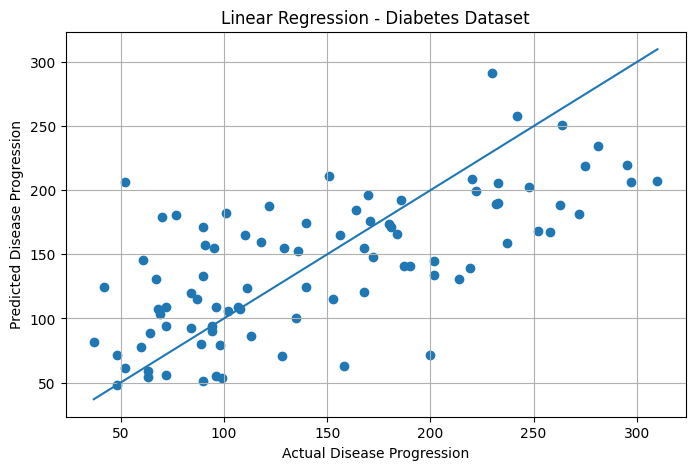


Linear Regression Completed Successfully


In [1]:
# Import required libraries
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Load Diabetes dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Display dataset
print("Dataset:")
print(df.head())

# Independent variables
X = df.drop("target", axis=1)

# Dependent variable
y = df["target"]

print("\nDataset Shape:", df.shape)
print("Number of Independent Variables:", X.shape[1])

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Display model parameters
print("\nIntercept:", model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

# Display actual values
print("\nActual Values:")
print(y_test.values)

# Display predicted values
print("\nPredicted Values:")
print(y_pred)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))

# Plot Actual vs Predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Linear Regression - Diabetes Dataset")
plt.grid(True)

plt.show()

print("\nLinear Regression Completed Successfully")